# C03-GN — GMM (RFM + AOV + Diversity + Tenure → log1p mọi biến → StandardScaler → PCA 90%)

Thí nghiệm **C03-GN** (người chạy: Thuận, hạn nội bộ 18/11/2026) theo chiến lược model. So với C01 (RFM + AOV + Diversity), **chỉ thêm Tenure** (độ dài quan hệ = ngày mua cuối − ngày mua đầu). Quy trình: làm sạch → feature cấp khách → RFM + AOV + Diversity + Tenure → log1p mọi biến → StandardScaler → PCA 90% → GMM. Đây là nhóm C; C02, C03, C04 so với C01 (RFM + AOV + Diversity).

Nguồn biến trong `customer_features.csv` của nhóm: AOV = `avg_order_value`, Diversity = `n_stock_codes`, QtyPerOrder = `avg_quantity_per_order`, Tenure = `observed_span_days` (ngày mua cuối − ngày mua đầu, theo mô tả của chiến lược; khác `observed_tenure_days` = ngày tham chiếu − ngày mua đầu).

**Lưu ý về mã `-GN`:** trong repo, nhóm làm các thí nghiệm `-GN` bằng **GMM** (A02-GN, B02-GN của An; B01-GN, C01-GN của Nguyên; A04 của Hiếu), nên notebook này cũng dùng GMM, cùng quy trình quét k × covariance_type và chọn theo BIC.

## Params

In [1]:
FEATURES = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity', 'Tenure']
FEATURES_PARENT = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity']   # C01, để đối chiếu cùng tham số
RANDOM_STATE = 42
N_INIT = 10                # giống A02-GN (An) và B01-GN (Nguyên)
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01     # điều kiện chọn: mỗi cụm >= 1% số khách (giống A02-GN)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A02-KM, A02-GN, B01-GN...)
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# Đổi tên cột cho dễ đọc: AOV, Diversity, QtyPerOrder, Tenure
RENAME = {"avg_order_value": "AOV", "n_stock_codes": "Diversity", "avg_quantity_per_order": "QtyPerOrder", "observed_span_days": "Tenure"}
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns=RENAME)
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 6)


,Recency,Frequency,Monetary,AOV,Diversity,Tenure
count,4327.00,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49,130.59
std,99.98,7.64,8441.89,466.49,85.31,132.24
min,1.00,1.00,2.90,2.90,1.00,0.00
25%,18.00,1.00,301.52,175.47,16.00,0.00
50%,51.00,2.00,657.90,286.70,35.00,92.14
75%,143.00,5.00,1624.10,421.99,77.00,252.03
max,374.00,206.00,278748.02,14844.77,1784.00,373.10


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Độ lệch của các biến trước và sau `log1p`

In [3]:
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew(), "zero_pct": (100 * (X == 0).mean()).round(2)}).round(2)
skew

,skew_raw,skew_log1p,zero_pct
Recency,1.25,-0.33,0.0
Frequency,11.95,1.21,0.0
Monetary,21.04,0.35,0.0
AOV,11.94,-0.00,0.0
Diversity,6.92,-0.24,0.0
Tenure,0.46,-0.39,34.8


**Nhận xét:** `log1p` kéo độ lệch của Monetary từ 21.04 xuống 0.35; độ lệch sau log1p của mọi biến nằm trong [-0.39; 1.21]. Biến có giá trị 0: Tenure (34.8% khách) (`log1p(0) = 0`, tạo một đỉnh ở giá trị thấp nhất).

## Tiền xử lý

RFM + AOV + Diversity + Tenure → log1p mọi biến → StandardScaler → PCA 90%.

In [4]:
prep = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 4)
Phương sai từng PC: [0.6149 0.1858 0.0927 0.0657] | giữ lại: 0.9592


## Quét k × covariance_type

Chỉ số chọn là **BIC** (thấp hơn tốt hơn). Silhouette/DBI/CHI tính trên đầu vào mô hình, chỉ để tham khảo.

Chọn: full, k=7, BIC=26,346.7, Silhouette=0.1026, cụm nhỏ nhất=45


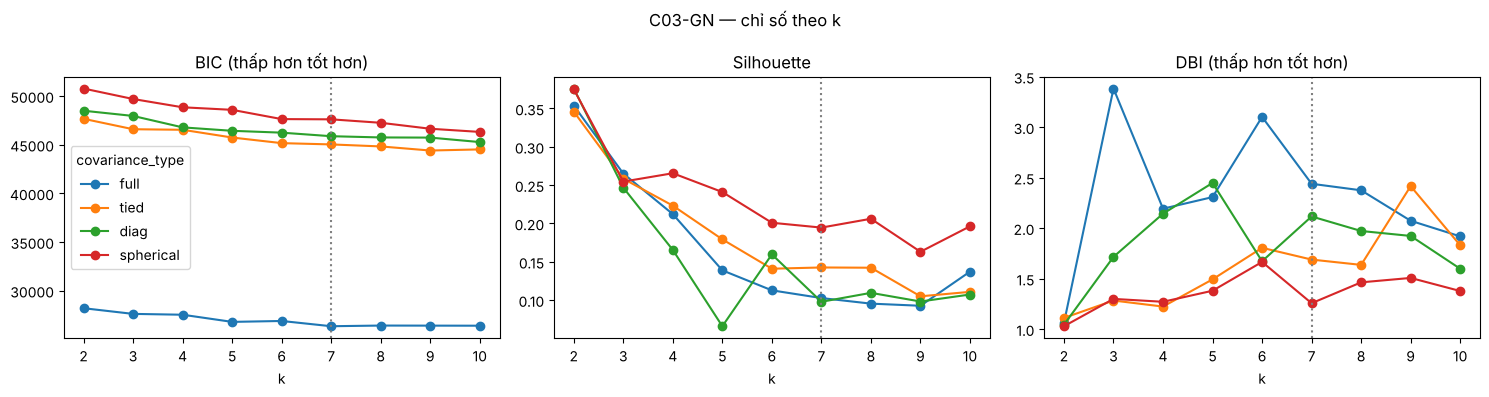

,covariance_type,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
5,full,7,26346.6835,25683.9300,0.1026,2.4396,785.0098,45,True
8,full,10,26400.5343,25451.0124,0.1371,1.9187,910.3859,45,True
7,full,9,26408.0496,25554.1172,0.0925,2.0733,748.3637,30,True
6,full,8,26416.0764,25657.7334,0.0953,2.3749,792.0298,45,True
3,full,5,26792.9960,26321.4214,0.1388,2.3076,1031.5178,268,True
4,full,6,26886.2428,26319.0787,0.1127,3.1018,817.6686,45,True
2,full,4,27528.1927,27152.2075,0.2121,2.1928,1299.2743,267,True
1,full,3,27614.2625,27333.8668,0.2651,3.3829,1401.0611,570,True
0,full,2,28198.1605,28013.3542,0.3538,1.0622,2622.4791,1504,True
16,tied,9,44399.0252,44054.9032,0.1049,2.4162,828.8267,50,True


In [5]:
def sweep(Xs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                 reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Xs)
            lab = gm.predict(Xs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Xs), "AIC": gm.aic(Xs),
                         "Silhouette": silhouette_score(Xs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Xs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Xs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col + (" (thấp hơn tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("C03-GN — chỉ số theo k"); plt.tight_layout()
plt.savefig(FIG / "gmm_metrics.png", dpi=150); plt.show()
res.sort_values("BIC").head(10).round(4)

**Nhận xét:** BIC thấp nhất trong các cấu hình hội tụ và có cụm ≥ 1% khách là `full`, k=7 (BIC 26,346.7); cụm nhỏ nhất 45 khách. Silhouette 0.1026, DBI 2.4396. Silhouette thấp: GMM là mô hình xác suất, các cụm chồng lấn nên chỉ số này chỉ để tham khảo.

## Train mô hình cuối

In [6]:
GM_ARGS = dict(n_components=int(best["k"]), covariance_type=best["covariance_type"], n_init=N_INIT, max_iter=MAX_ITER,
               tol=TOL, reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE)
model = Pipeline([("prep", Pipeline([
        ("log1p", FunctionTransformer(np.log1p, validate=True)),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
    ])),
                  ("gmm", GaussianMixture(**GM_ARGS))]).fit(X.values)
gm = model["gmm"]
assert np.allclose(model["prep"].transform(X.values), Z)
labels = gm.predict(Z)
proba = gm.predict_proba(Z)
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_)
print("Số khách mỗi cụm:", dict(enumerate(np.bincount(labels).tolist())))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Hội tụ: True | số vòng EM: 36
Số khách mỗi cụm: {0: 220, 1: 879, 2: 1210, 3: 625, 4: 45, 5: 580, 6: 768}
Silhouette: 0.1026 | DBI: 2.4396


## Hồ sơ cụm (trung vị trên thang gốc)

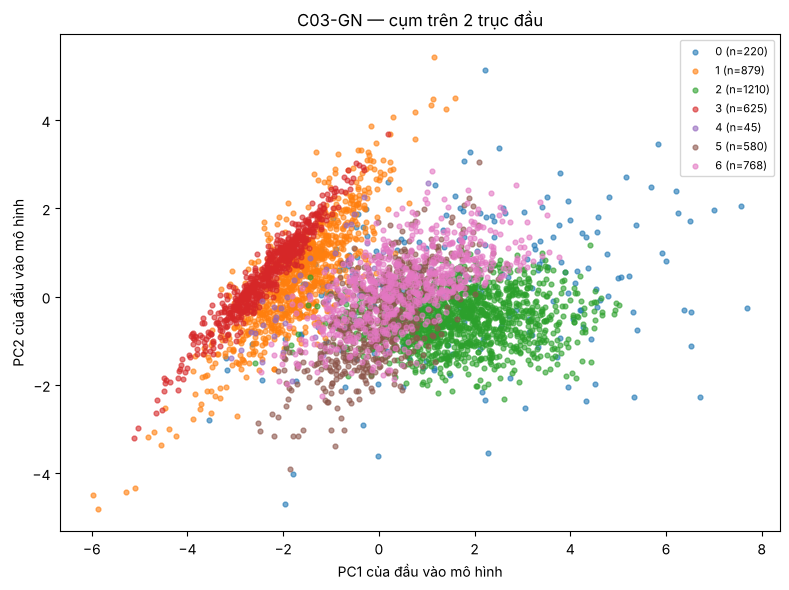

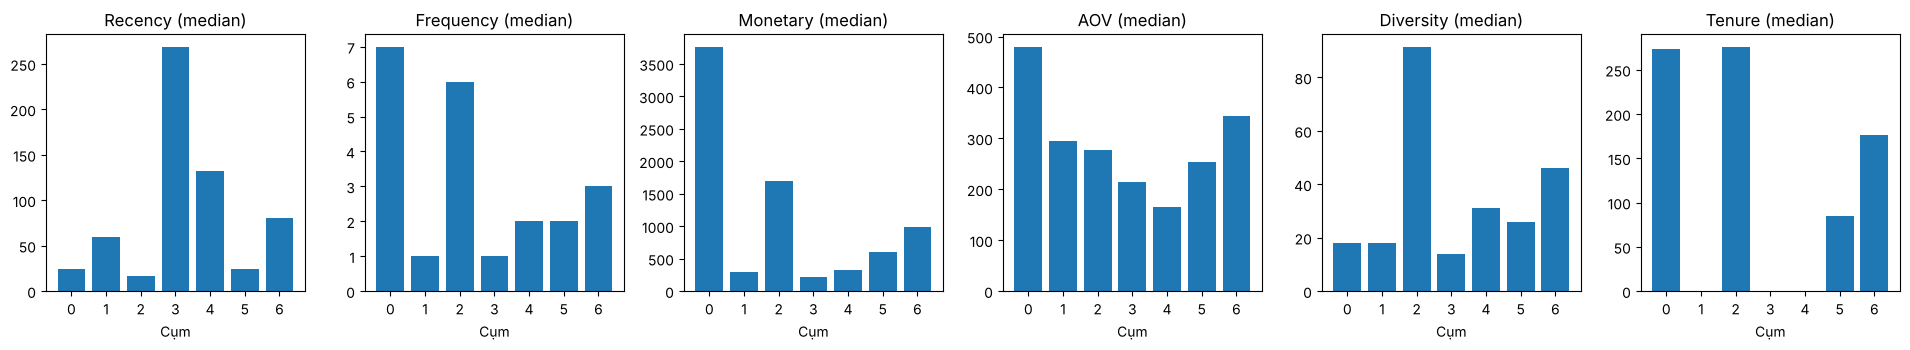

,customers,Recency,Frequency,Monetary,AOV,Diversity,Tenure,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,
0,220,24.5,7.0,3764.9,480.0,18.0,273.1,5.1,39.1
1,879,60.0,1.0,294.8,294.8,18.0,0.0,20.3,4.4
2,1210,17.0,6.0,1696.1,276.7,91.5,276.0,28.0,35.6
3,625,269.0,1.0,215.0,215.0,14.0,0.0,14.4,2.0
4,45,132.0,2.0,328.6,164.3,31.0,0.0,1.0,0.2
5,580,24.0,2.0,598.1,254.2,26.0,84.9,13.4,5.3
6,768,81.0,3.0,991.9,344.4,46.0,176.8,17.8,13.3


In [7]:
agg = {f: (f, "median") for f in FEATURES}
prof = X.assign(cluster=labels).groupby("cluster").agg(customers=("Monetary", "size"), Monetary_sum=("Monetary", "sum"), **agg)
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("C03-GN — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "gmm_clusters_pca.png", dpi=150); plt.show()

# Trung vị từng biến theo cụm (thang gốc)
fig, axes = plt.subplots(1, len(FEATURES), figsize=(3.2 * len(FEATURES), 3.6))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); plt.savefig(FIG / "feature_comparison.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 0 có Monetary trung vị cao nhất (3,765), gồm 220 khách (5.1%) nhưng chiếm 39.1% tổng Monetary. Cụm 2 đông nhất (28.0% khách, Recency trung vị 17 ngày).

## Đối chiếu với C01 (cùng tham số model)

In [8]:
# Chẩn đoán so với C01: giữ NGUYÊN tham số mô hình đã chọn, chỉ đổi tập feature về cấu hình C01 (FEATURES_PARENT).
# Đây không phải C01 được tune riêng, chỉ để đo riêng tác động của việc thêm feature.
prep_parent = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Zp = prep_parent.fit_transform(X[FEATURES_PARENT].values)
lp = GaussianMixture(**GM_ARGS).fit(Zp).predict(Zp)
ari_parent = adjusted_rand_score(labels, lp)
same_dims = Zp.shape[1] == Z.shape[1] and FEATURES_PARENT == FEATURES
same_geometry = same_dims and np.allclose(np.linalg.norm(Z[:300, None] - Z[None, :300], axis=2),
                                          np.linalg.norm(Zp[:300, None] - Zp[None, :300], axis=2), atol=1e-8)
print(f"C03: {Z.shape[1]} chiều | C01: {Zp.shape[1]} chiều")
print(f"ARI giữa nhãn C03 và nhãn C01 (cùng tham số): {ari_parent:.4f}")
print("Cùng hình học khoảng cách:", same_geometry)

C03: 4 chiều | C01: 3 chiều
ARI giữa nhãn C03 và nhãn C01 (cùng tham số): 0.3939
Cùng hình học khoảng cách: False


**Nhận xét:** ARI giữa C03 và C01 (cùng tham số) = 0.3939; số chiều đầu vào 4 so với 3. Nhãn khác nhiều: việc thêm feature làm đổi phân cụm đáng kể.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "gmm_c03_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_c03_labels.csv", index=False)
joblib.dump(model, "gmm_c03_model.pkl")
params = {"experiment": "C03-GN", "features": FEATURES, "feature_sources": {k: v for v, k in RENAME.items() if k in FEATURES}, "transform": 'log1p',
          "scaler": "StandardScaler", "pca": 0.9,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(model["prep"]["pca"].explained_variance_ratio_.sum()),
          "covariance_type": best["covariance_type"], "k": int(best["k"]), "bic": float(best["BIC"]), "aic": float(best["AIC"]),
          "silhouette": float(best["Silhouette"]), "dbi": float(best["DBI"]), "chi": float(best["CHI"]),
          "min_cluster": int(best["min_cluster"]), "converged": bool(gm.converged_), "n_iter": int(gm.n_iter_),
          "gmm_params": {k: v for k, v in gm.get_params().items()},
          "ari_vs_parent_fixed_params": {"parent": "C01", "ari": float(ari_parent)}}
json.dump(params, open(OUT / "gmm_c03_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2, default=str)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['gmm_c03_grid.csv', 'gmm_c03_labels.csv', 'gmm_c03_params.json']


**Kết luận C03-GN:** GMM `full` k=7 (BIC 26,346.7) trên 4 chiều đầu vào. ARI với C01 (cùng tham số) = 0.3939. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên thang gốc để so sánh.